# (1) Giới thiệu

## Phân tích cảm xúc VLSP — ba pipeline, sáu lượt

So sánh **TF-IDF → TruncatedSVD → LinearSVC**, **CBOW → GRU**, **PhoBERT-base-v2**, mỗi pipeline trên Base/Augmented, cùng test. EDA riêng chạy CPU trước khi chốt xử lý. Full trên T4: GRU 4 epoch, PhoBERT 3 epoch khi thiếu lineage; smoke 1 epoch. Có lineage: validation chung theo nhóm nguồn và chọn macro-F1. Không chọn cấu hình theo test.


## 1.1. Thư viện

Cài thư viện trước khi import. Phiên bản thực tế được lưu cùng kết quả để có thể đối chiếu môi trường.


In [ ]:
import subprocess
import sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'kagglehub>=0.3,<2', 'pyvi==0.1.1', 'scikit-learn>=1.4,<2', 'pandas>=2,<4',
    'matplotlib>=3.8,<4', 'transformers>=4.52,<5', 'py-vncorenlp==0.1.4',
    'torch>=2.6,<3', 'gensim>=4.4,<5', 'datasets>=3,<5', 'accelerate>=1,<2', 'joblib'])


0

## 1.2. Cấu hình và khả năng tái lập

Seed và siêu tham số được cố định trước huấn luyện. Đổi chế độ trước Run all; mỗi lượt có thư mục kết quả riêng.


In [ ]:
import copy
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import tempfile
import time
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from functools import lru_cache
from importlib.metadata import version
from itertools import groupby
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset as TorchDataset
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, matthews_corrcoef)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

SEED = 42
RUN_TRAINING = True
SMOKE_TEST = os.environ.get('NOTEBOOK_SMOKE', '0') == '1'
LABELS = [-1, 0, 1]
CLASS_NAMES = ['negative', 'neutral', 'positive']
DATA_DIR = None
AUGMENTATION_LINEAGE = None  # CSV aug_row,base_row; chỉ số dòng từ 0, không tính header.
WORD2VEC_FILE = None
DATASET_HANDLE = 'anhphmduy/vlsp-sentiment-dataset/versions/5'
OUTPUT_PARENT = Path('vlsp_oxford_results')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
RUN_DIR = OUTPUT_PARENT / (('smoke-' if SMOKE_TEST else 'full-') + RUN_ID)
RUN_DIR.mkdir(parents=True, exist_ok=False)
W2V_MAX_LENGTH = 300
MAX_VOCAB_SIZE = 10000
NEURAL_EPOCHS = 1 if SMOKE_TEST else 4
PHOBERT_EPOCHS = 1 if SMOKE_TEST else 3
PHOBERT_MAX_LENGTH = 256
PHOBERT_MODEL = 'vinai/phobert-base-v2'
PHOBERT_BATCH_SIZE = 8
PHOBERT_ACCUMULATION = 4  # effective batch 32 trên T4
ARCHITECTURES = ['TF-IDF + SVD + LinearSVC', 'CBOW + GRU', 'PhoBERT-base-v2']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
native_thread_limit = threadpool_limits(limits=2)

def seed_everything():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def release_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

seed_everything()
write_json(RUN_DIR / 'environment.json', {
    'python': sys.version, 'device': str(DEVICE),
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'packages': {name: version(name) for name in ['torch', 'transformers', 'pandas', 'numpy', 'scikit-learn', 'gensim']},
})
print('Thiết bị:', DEVICE, '| SMOKE:', SMOKE_TEST, '| Kết quả:', RUN_DIR)


Thiết bị: cuda | SMOKE: True | Kết quả: vlsp_oxford_results/smoke-20261121T164050Z


# (2) Tải và nạp dữ liệu

Tải phiên bản VLSP v5 hoặc dùng dữ liệu cục bộ. Đọc CSV/TSV theo header, kiểm tra nhãn và gán sample_id trước khi lọc.


In [ ]:
FILES = {
    "Base": ("vlsp_sentiment_train.csv",),
    "Augmented": ("vlsp_sentiment_train_augmented_v2.csv", "augmented_v2.csv"),
    "Test": ("vlsp_sentiment_test.csv",),
}

def locate_inputs(root):
    return {
        name: next((root / filename for filename in filenames if (root / filename).is_file()), None)
        for name, filenames in FILES.items()
    }

def resolve_inputs():
    if DATA_DIR is not None:
        root = Path(DATA_DIR).resolve()
    else:
        candidates = [
            Path("data"), Path("."),
            Path("/kaggle/input/vlsp-sentiment-dataset"),
            Path("/kaggle/input/datasets/anhphmduy/vlsp-sentiment-dataset"),
        ]
        root = next((p for p in candidates if all(locate_inputs(p).values())), None)
        if root is None:
            import kagglehub
            root = Path(kagglehub.dataset_download(DATASET_HANDLE))
            root = next(
                (p.parent for p in sorted(root.rglob(FILES["Base"][0]))
                 if all(locate_inputs(p.parent).values())),
                root,
            )
        root = root.resolve()
    paths = locate_inputs(root)
    missing = ["/".join(FILES[name]) for name, path in paths.items() if path is None]
    if missing:
        raise FileNotFoundError(f"Thiếu dữ liệu VLSP tại {root}: {', '.join(missing)}")
    return root, paths

def read_vlsp(path, split):
    for delimiter in ("\t", ","):
        header = pd.read_csv(path, sep=delimiter, encoding="utf-8-sig", nrows=0)
        if {"Class", "Data"}.issubset(header.columns.str.strip()):
            break
    else:
        raise ValueError(f"{path.name} cần hai cột Class và Data, phân tách bằng tab hoặc dấu phẩy.")
    frame = pd.read_csv(path, sep=delimiter, encoding="utf-8-sig", keep_default_na=False, dtype=str)
    frame.columns = frame.columns.str.strip()
    frame = frame[["Class", "Data"]].copy()
    labels = pd.to_numeric(frame["Class"], errors="coerce")
    invalid = ~labels.isin(LABELS)
    if frame.empty or invalid.any():
        raise ValueError(f"{path.name}: {int(invalid.sum())} nhãn sai hoặc tập rỗng.")
    frame["label"] = labels.astype(int)
    frame = frame.rename(columns={"Data": "text"})
    frame["row"] = np.arange(len(frame))
    frame["sample_id"] = split.lower() + "-" + frame["row"].astype(str)
    return frame[["sample_id", "row", "label", "text"]]

data_root, paths = resolve_inputs()
raw = {name: read_vlsp(path, name) for name, path in paths.items()}
display(pd.DataFrame({name: frame["label"].value_counts() for name, frame in raw.items()})
        .reindex(LABELS).fillna(0).astype(int))


Using Colab cache for faster access to the 'vlsp-sentiment-dataset' dataset.


,Base,Augmented,Test
label,,,
-1,1700,3385,350
0,1700,3387,350
1,1700,3377,350


# (3) Tiền xử lý và chia tập theo kết quả EDA

Áp dụng các quyết định đã chốt trong notebook EDA CPU: nền chung NFC và khoảng trắng, giữ văn bản gốc; đầu vào riêng cho TF-IDF, CBOW và PhoBERT. Không thay teencode/emoticon thành từ cảm xúc và không rút chữ kéo dài khi ngữ cảnh chưa đủ rõ. Kiểm toán lại trước khi chia tập.

## Kết luận EDA và quyết định trước huấn luyện

| Quan sát / bằng chứng CPU | Quyết định | Giới hạn |
|---|---|---|
| NFC/khoảng trắng thay đổi 213/5.100 câu Base và 1/10.149 câu Augmented; không tạo câu rỗng hoặc nhóm va chạm mới | Chuẩn NFC/khoảng trắng, giữ văn bản gốc | Soát lại trùng/giao tập sau xử lý; không suy chất lượng nhãn từ tần suất |
| TF-IDF word+emoticon: 5.000 đặc trưng giữ 60,35%/63,78% lượt đặc trưng-văn bản Base/Augmented; 20.000 giữ 76,07%/78,52%; câu mất hết đặc trưng giảm 4→2 và 9→3 | Chữ thường; unigram/bigram; giữ emoticon bằng analyzer đã khảo sát; max_features=20.000, min_df=1, sparse float32 và dense theo minibatch | Coverage đo trên chính tập fit, không phải tổng số token hoặc bảo đảm tăng F1; batch 128 dense khoảng 10,24 MB, chưa gồm activation CNN |
| CBOW ở 300 từ cắt 16/5.100 câu Base, 27/10.149 câu Augmented; mất 5,66%/3,16% lượt token vì có đuôi dài | Giữ giới hạn 300, PyVi sau chữ thường; vocabulary 10.000 fit riêng, PAD/UNK, embedding trainable độc lập | Tỷ lệ câu bị cắt nhỏ không có nghĩa lượng nội dung mất nhỏ; OOV pretrained khác UNK vocabulary |
| PhoBERT 256 token cắt 22 câu Base và 36 câu Augmented, mất 6,10%/3,76% lượt token; chữ thường làm tổng BPE tăng 172.312→174.840 và 328.094→331.324 | Giữ hoa/thường, RDRSegmenter trước BPE, giới hạn 256 gồm token đặc biệt | Giới hạn kiến trúc; không loại câu dài để làm đẹp chỉ số |
| Thay teencode chỉ giảm OOV CBOW Base từ 27.373 xuống 27.360; emoticon xuất hiện ở cả ba lớp, ngữ cảnh có thể mỉa mai | Không thay đồng loạt teencode/emoticon bằng từ có nghĩa định sẵn; không rút chữ kéo dài hoặc xóa ký hiệu | Không khẳng định các quy tắc này luôn có hại; muốn kết luận về F1 cần thí nghiệm validation riêng |

Các lựa chọn được chốt từ Base/Augmented và chi phí biểu diễn, trước khi đo kết quả mô hình mới. Không dùng nhãn test hoặc điểm test để chọn xử lý. Từng quy tắc ứng viên trong bảng tác động đều được áp dụng cùng nền NFC/khoảng trắng; số dòng thay đổi được so với dữ liệu gốc, các nhóm không cộng được với nhau.



In [ ]:
POLICY = {'version': 'vlsp-eda-v3-six-raincloud', 'common': ['NFC', 'collapse_whitespace', 'preserve_original_text', 'preserve_negation_numbers_symbols'], 'semantic_replacements': False, 'elongation_reduction': False, 'tfidf': {'lowercase': True, 'token_pattern': '(?u)(?::[-]?[)(d]|\\^\\^|t\\.t|\\b\\w+\\b)', 'ngram_range': [1, 2], 'max_features': 20000, 'min_df': 1, 'sublinear_tf': True, 'svd_max_components': 300}, 'cbow': {'lowercase': True, 'segmenter': 'PyVi', 'vocabulary_limit': 10000, 'max_length': 300, 'pad': 0, 'unk': 1}, 'phobert': {'preserve_case': True, 'segmenter': 'RDRSegmenter', 'max_length': 256, 'effective_batch': 32}, 'eda_sources': {'Base': '669f584a9fd149ebf7b4bc8aa16bbacff3ee14e0b05512fd035d6f33a3f4b417', 'Augmented': '67220874e2d224bfe04dec0b37791addf72c6dbb54b5b13f355327bb8e2b4477', 'Test': '7252546b2a289eccaa3e6a4748cc021b567442a7f3352c468ff2cbe8e353e6c8'}, 'eda_notebook_code_sha256': '0e8ff2afca0d5fe4f1d5d36c7a6685ca647de4e87a49e7db3b39b288f6725722', 'architectures': ['TF-IDF + SVD + LinearSVC', 'CBOW + GRU', 'PhoBERT-base-v2']}
PREPROCESSING_VERSION = 'vlsp-eda-v3-six-raincloud'
# Các quyết định cụ thể và bằng chứng EDA được đóng gói cùng lượt chạy.
def normalize_text(text):
    return ' '.join(unicodedata.normalize('NFC', text).split())

def text_key(text):
    return normalize_text(text).casefold()

def audit_inputs(frames):
    prepared = {
        name: frame.assign(
            text_clean=frame["text"].map(normalize_text),
            raw_key=frame["text"].map(
                lambda text: " ".join(unicodedata.normalize("NFC", text).casefold().split())
            ),
        )
        for name, frame in frames.items()
    }
    for frame in prepared.values():
        frame["clean_key"] = frame["text_clean"].map(text_key)

    test_frame = prepared["Test"]
    if test_frame["clean_key"].eq("").any():
        raise ValueError("Test có văn bản rỗng sau chuẩn hóa. Kiểm tra các dòng nguồn trước khi chạy.")

    audit = []
    development = pd.concat([prepared["Base"], prepared["Augmented"]])
    conflicting = set(development.groupby("clean_key")["label"].nunique().loc[lambda s: s > 1].index)
    cleaned = {"Test": test_frame.copy()}
    for name, frame in prepared.items():
        empty = frame["clean_key"].eq("")
        raw_overlap = frame["raw_key"].isin(test_frame["raw_key"]) & ~empty
        overlap = frame["clean_key"].isin(test_frame["clean_key"]) & ~empty
        conflict = frame["clean_key"].isin(conflicting) & ~empty & ~raw_overlap & ~overlap
        entry = {
            "split": name,
            "input_rows": len(frame),
            "raw_blank": int(frame["raw_key"].eq("").sum()),
            "empty_after_cleaning": int(empty.sum()),
            "raw_duplicate_extras": int(frame.loc[~empty, "raw_key"].duplicated().sum()),
            "normalized_duplicate_extras": int(frame.loc[~empty, "clean_key"].duplicated().sum()),
            "raw_overlap_with_test": None if name == "Test" else int(raw_overlap.sum()),
            "normalized_overlap_with_test": None if name == "Test" else int(overlap.sum()),
            "conflicting_dev_labels": None if name == "Test" else int(conflict.sum()),
        }
        if name != "Test":
            cleaned[name] = frame.loc[~(empty | raw_overlap | overlap | conflict)].copy()
        else:
            entry["test_conflicting_keys"] = int((frame.groupby("clean_key")["label"].nunique() > 1).sum())
        audit.append(entry)
    return cleaned, pd.DataFrame(audit).set_index("split")

assert all(sha256_file(paths[name]) == expected for name, expected in POLICY['eda_sources'].items()), 'Nguồn dữ liệu thay đổi so với EDA; cần khảo sát lại.'
assert normalize_text('Ko tốt :)) ❤️') == 'Ko tốt :)) ❤️'
assert normalize_text('  KHÔNG   tốt! ') == 'KHÔNG tốt!'
write_json(RUN_DIR / 'preprocessing_policy.json', POLICY)
cleaned, audit = audit_inputs(raw)
display(audit)
examples = cleaned["Base"].loc[lambda f: f["text"].ne(f["text_clean"]), ["text", "text_clean"]]
display(examples.head(5))


,input_rows,raw_blank,empty_after_cleaning,raw_duplicate_extras,normalized_duplicate_extras,raw_overlap_with_test,normalized_overlap_with_test,conflicting_dev_labels,test_conflicting_keys
split,,,,,,,,,
Base,5100,0,0,48,48,23.0,23.0,0.0,NaN
Augmented,10149,0,0,161,161,33.0,33.0,2.0,NaN
Test,1050,0,0,0,0,NaN,NaN,NaN,0.0


,text,text_clean
63,Cái mặt đồng hồ chả hợp với dây da quái gì _,Cái mặt đồng hồ chả hợp với dây da quái gì _
88,"S6 edge iron man vẫn đẹp hơn, màu đen như n...","S6 edge iron man vẫn đẹp hơn, màu đen như này ..."
119,Kekeke...mình thì không nghĩ thế đâu..nhìn con...,Kekeke...mình thì không nghĩ thế đâu..nhìn con...
122,Thiết kế ý tưởng tương tự nhưng xấu hơn cả iph...,Thiết kế ý tưởng tương tự nhưng xấu hơn cả iph...
144,"Tôi thì không thích BB, vì nhỏ thư ký không k...","Tôi thì không thích BB, vì nhỏ thư ký không kh..."


## 3.1. Validation theo nhóm nguồn

Nếu có lineage, giữ riêng một fold Base và loại mọi câu Augmented thuộc nhóm nguồn validation. Thiếu lineage: epoch cố định, không early stopping hay chọn checkpoint bằng test.


In [ ]:
def read_lineage(path, frames):
    mapping = pd.read_csv(path)
    columns = ["aug_row", "base_row"]
    if not set(columns).issubset(mapping):
        raise ValueError("Lineage cần hai cột aug_row và base_row.")
    numbers = mapping[columns].apply(pd.to_numeric, errors="coerce")
    for column, name in zip(columns, ("Augmented", "Base")):
        valid = numbers[column].isin(frames[name]["row"])
        if not valid.all():
            raise ValueError(f"Lineage có chỉ số {column} không hợp lệ.")
    numbers = numbers.astype(int).set_index("aug_row", verify_integrity=True)
    if set(numbers.index) != set(frames["Augmented"]["row"]):
        raise ValueError("Lineage phải ánh xạ đúng một lần cho mọi dòng Augmented.")
    parents = frames["Augmented"]["row"].map(numbers["base_row"])
    expected = parents.map(frames["Base"].set_index("row")["label"])
    if not expected.eq(frames["Augmented"]["label"]).all():
        raise ValueError("Lineage có dòng Augmented mang nhãn khác dòng Base cha.")
    return numbers["base_row"]

def unique_texts(frame):
    return frame.drop_duplicates("clean_key").reset_index(drop=True)

def partition_frames(development, frames, lineage_path):
    base = development["Base"]
    aug = development["Augmented"]
    validation = None
    if lineage_path is not None:
        parent_rows = read_lineage(lineage_path, frames)
        base_groups = frames["Base"].set_index("row")["text"].map(normalize_text).map(text_key)
        folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        _, val_idx = next(folds.split(base, base["label"], groups=base["clean_key"]))
        validation = unique_texts(base.iloc[val_idx])
        val_keys = set(validation["clean_key"])
        val_raw_keys = set(validation["raw_key"])
        aug = aug.loc[aug["row"].map(parent_rows).isin(base["row"])]
        base = base.loc[~base["clean_key"].isin(val_keys)]
        parent_keys = aug["row"].map(parent_rows).map(base_groups)
        validation_descendants = aug.loc[parent_keys.isin(val_keys)]
        held_out_keys = val_keys | set(validation_descendants["clean_key"])
        held_out_raw = val_raw_keys | set(validation_descendants["raw_key"])
        aug = aug.loc[~(parent_keys.isin(val_keys) | aug["clean_key"].isin(held_out_keys)
                        | aug["raw_key"].isin(held_out_raw))]
    return {"Base": unique_texts(base), "Augmented": unique_texts(aug)}, validation

lineage_path = Path(AUGMENTATION_LINEAGE) if AUGMENTATION_LINEAGE is not None else None
if lineage_path is None and (data_root / "augmentation_lineage.csv").is_file():
    lineage_path = data_root / "augmentation_lineage.csv"
training, validation = partition_frames(cleaned, raw, lineage_path)
test = cleaned["Test"].reset_index(drop=True)

partitions = {**training, "Test": test}
if validation is not None:
    partitions["Validation"] = validation
for name, frame in partitions.items():
    if set(frame["label"]) != set(LABELS):
        raise ValueError(f"{name} cần đủ cả ba lớp sau kiểm toán và chia tập.")
for frame in training.values():
    for holdout in (test,) if validation is None else (test, validation):
        for key in ("raw_key", "clean_key"):
            if set(frame[key]) & set(holdout[key]):
                raise ValueError(f"Phát hiện giao nhau giữa train và holdout theo {key}.")

print("Chế độ:", "validation theo nhóm nguồn" if validation is not None else "cấu hình cố định, thiếu lineage")
audit["fit_or_test_rows"] = pd.Series({name: len(frame) for name, frame in {"Test": test, **training}.items()})
display(pd.DataFrame({name: frame["label"].value_counts() for name, frame in partitions.items()})
        .reindex(LABELS).fillna(0).astype(int))


Chế độ: cấu hình cố định, thiếu lineage


,Base,Augmented,Test
label,,,
-1,1686,3345,350
0,1697,3377,350
1,1659,3256,350


## 3.2. Biểu diễn riêng theo embedder

TF-IDF: chữ thường và analyzer đã khảo sát. CBOW: chữ thường rồi PyVi, vocabulary fit riêng và PAD/UNK. PhoBERT: giữ hoa/thường, RDRSegmenter trước BPE, tối đa 256 token. Không fit bộ xử lý trên test.


In [ ]:
from pyvi import ViTokenizer
import py_vncorenlp
from transformers import AutoTokenizer

if shutil.which('java') is None:
    raise RuntimeError('Cần Java cho VnCoreNLP; trên Colab cài openjdk-17-jre-headless rồi Run all.')
os.environ.setdefault('JAVA_HOME', str(Path(shutil.which('java')).resolve().parent.parent))
segmenter_dir = Path('vncorenlp').resolve()
segmenter_dir.mkdir(exist_ok=True)
working_dir = Path.cwd()
try:
    import urllib.request
    # py_vncorenlp.download_model dùng wget không kiểm tra exit status.
    for relative in ['VnCoreNLP-1.2.jar','models/wordsegmenter/vi-vocab','models/wordsegmenter/wordsegmenter.rdr']:
        target = segmenter_dir / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        if not target.is_file() or target.stat().st_size == 0:
            for attempt in range(3):
                try:
                    request = urllib.request.Request('https://raw.githubusercontent.com/vncorenlp/VnCoreNLP/master/' + relative, headers={'User-Agent':'VLSP-notebook'})
                    with urllib.request.urlopen(request, timeout=45) as response, target.with_suffix(target.suffix + '.part').open('wb') as output:
                        shutil.copyfileobj(response, output)
                    target.with_suffix(target.suffix + '.part').replace(target)
                    assert target.stat().st_size > 0
                    break
                except Exception:
                    if attempt == 2: raise
                    time.sleep(2)
        if relative.endswith('.jar'):
            with target.open('rb') as stream:
                assert stream.read(2) == b'PK', 'VnCoreNLP JAR không hợp lệ'

    segmenter = py_vncorenlp.VnCoreNLP(annotators=['wseg'], save_dir=str(segmenter_dir))
finally:
    os.chdir(working_dir)

@lru_cache(maxsize=None)
def phobert_words(text):
    return ' '.join(segmenter.word_segment(text))

for frame in partitions.values():
    frame['text_tfidf'] = frame.text_clean.str.lower()
    frame['words'] = frame.text_clean.str.lower().map(ViTokenizer.tokenize)
    frame['phobert_words'] = frame.text_clean.map(phobert_words)
phobert_tokenizer = AutoTokenizer.from_pretrained(PHOBERT_MODEL, use_fast=False)
full_partitions = {name: frame.copy() for name, frame in partitions.items()}
eda_dir = RUN_DIR / 'eda'
eda_dir.mkdir()

def save_text_figure(figure, filename):
    figure.savefig(eda_dir / filename, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(figure)

def length_summary(field, count_tokens, limit):
    rows = []
    for name, frame in full_partitions.items():
        if name == 'Test':
            continue
        sizes = frame[field].map(count_tokens)
        rows.append({'split': name, 'limit': limit, 'median': float(sizes.median()),
                     'p95': float(sizes.quantile(.95)), 'p99': float(sizes.quantile(.99)),
                     'over_limit': int(sizes.gt(limit).sum()), 'over_limit_pct': float(100 * sizes.gt(limit).mean())})
    return pd.DataFrame(rows).set_index('split')

word_lengths = length_summary('words', lambda text: len(text.split()), W2V_MAX_LENGTH)
bpe_lengths = length_summary('phobert_words', lambda text: len(phobert_tokenizer.encode(text)), PHOBERT_MAX_LENGTH)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

# (4) Kiểm tra sau áp dụng quyết định EDA

EDA khám phá và đối chiếu quy tắc đã thực hiện trước trong sentimentanalysis_eda.ipynb. Các bảng dưới đây kiểm toán lại dữ liệu và biểu diễn thực tế của lần huấn luyện; không dùng để chọn mô hình bằng test.


characters  whitespace_units
label quantile                              
-1    0.50            77.0              17.0
      0.95           340.1              75.0
      1.00          1532.0             356.0
 0    0.50           102.0              24.0
      0.95           416.1              92.0
      1.00         13164.0            2885.0
 1    0.50            69.0              16.0
      0.95           298.0              67.0
      1.00          2753.0             631.0

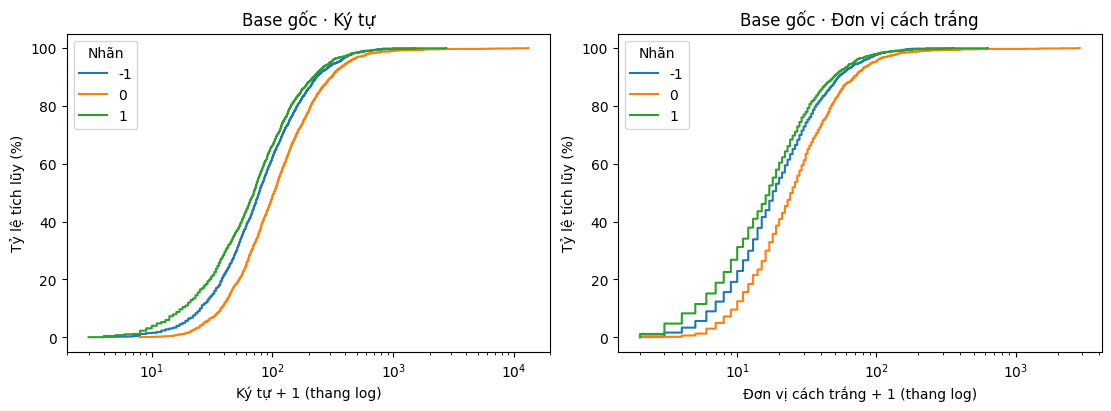

In [ ]:
base_raw = raw["Base"]
lengths = pd.DataFrame({
    "label": base_raw["label"],
    "characters": base_raw["text"].str.len(),
    "whitespace_units": base_raw["text"].str.split().str.len(),
})
raw_length_summary = lengths.groupby("label")[["characters", "whitespace_units"]].quantile([0.5, 0.95, 1])
raw_length_summary = raw_length_summary.rename_axis(["label", "quantile"])
raw_length_summary.to_csv(eda_dir / "raw_length_quantiles.csv")
display(raw_length_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, field, unit in zip(axes, ("characters", "whitespace_units"), ("Ký tự", "Đơn vị cách trắng")):
    for label, frame in lengths.groupby("label"):
        values = np.sort(frame[field].to_numpy())
        ax.step(1 + values, 100 * np.arange(1, len(values) + 1) / len(values), where="post", label=str(label))
    ax.set(xscale="log", xlabel=f"{unit} + 1 (thang log)", ylabel="Tỷ lệ tích lũy (%)", title=f"Base gốc · {unit}")
    ax.legend(title="Nhãn")
save_text_figure(fig, "eda-raw-lengths.png")


## 4.1. Phân bố nhãn và các lý do lọc

So sánh dữ liệu gốc với tập fit. Các nhóm kiểm toán có thể chồng lấn, vì vậy không cộng các cột để suy ra số dòng bị loại.


label,-1,0,1
stage,,,
Base gốc,1700,1700,1700
Base fit,1686,1697,1659
Augmented gốc,3385,3387,3377
Augmented fit,3345,3377,3256


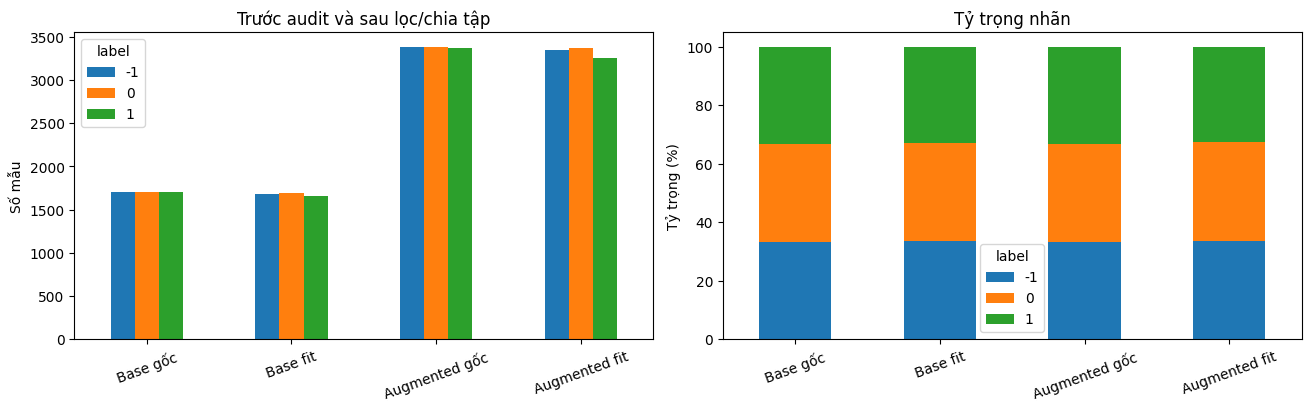

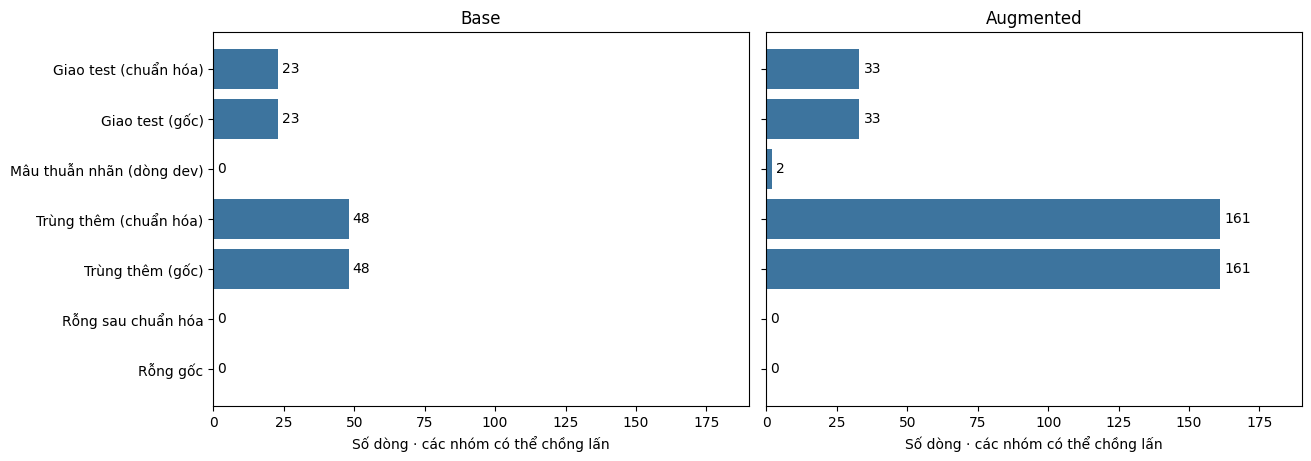

In [ ]:
stages = {
    "Base gốc": raw["Base"], "Base fit": training["Base"],
    "Augmented gốc": raw["Augmented"], "Augmented fit": training["Augmented"],
}
if validation is not None:
    stages["Validation"] = validation
label_counts = pd.DataFrame({
    stage: frame["label"].value_counts().reindex(LABELS, fill_value=0)
    for stage, frame in stages.items()
}).T.rename_axis("stage")
label_counts.to_csv(eda_dir / "label_counts.csv")
display(label_counts)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
label_counts.plot.bar(ax=axes[0], rot=20)
axes[0].set(ylabel="Số mẫu", xlabel="", title="Trước audit và sau lọc/chia tập")
label_counts.div(label_counts.sum(axis=1), axis=0).mul(100).plot.bar(stacked=True, ax=axes[1], rot=20)
axes[1].set(ylabel="Tỷ trọng (%)", xlabel="", title="Tỷ trọng nhãn")
save_text_figure(fig, "eda-labels.png")

audit_fields = {
    "raw_blank": "Rỗng gốc",
    "empty_after_cleaning": "Rỗng sau chuẩn hóa",
    "raw_duplicate_extras": "Trùng thêm (gốc)",
    "normalized_duplicate_extras": "Trùng thêm (chuẩn hóa)",
    "conflicting_dev_labels": "Mâu thuẫn nhãn (dòng dev)",
    "raw_overlap_with_test": "Giao test (gốc)",
    "normalized_overlap_with_test": "Giao test (chuẩn hóa)",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
max_audit_count = audit.loc[["Base", "Augmented"], list(audit_fields)].max().max()
for ax, name in zip(axes, ("Base", "Augmented")):
    values = audit.loc[name, list(audit_fields)].rename(index=audit_fields).astype(int)
    bars = ax.barh(list(values.index), values.to_numpy(), color="#3d749e")
    ax.bar_label(bars, padding=3)
    ax.set(xlabel="Số dòng · các nhóm có thể chồng lấn", title=name, xlim=(0, max(1, max_audit_count) * 1.18))
audit.to_csv(eda_dir / "data_audit.csv")
save_text_figure(fig, "eda-cleaning-audit.png")


## 4.2. Từ vựng và tương đồng giữa các lớp

Thống kê từ/cụm từ và cosine giữa các centroid chỉ mô tả tập Base fit; không dùng test để chọn đặc trưng.


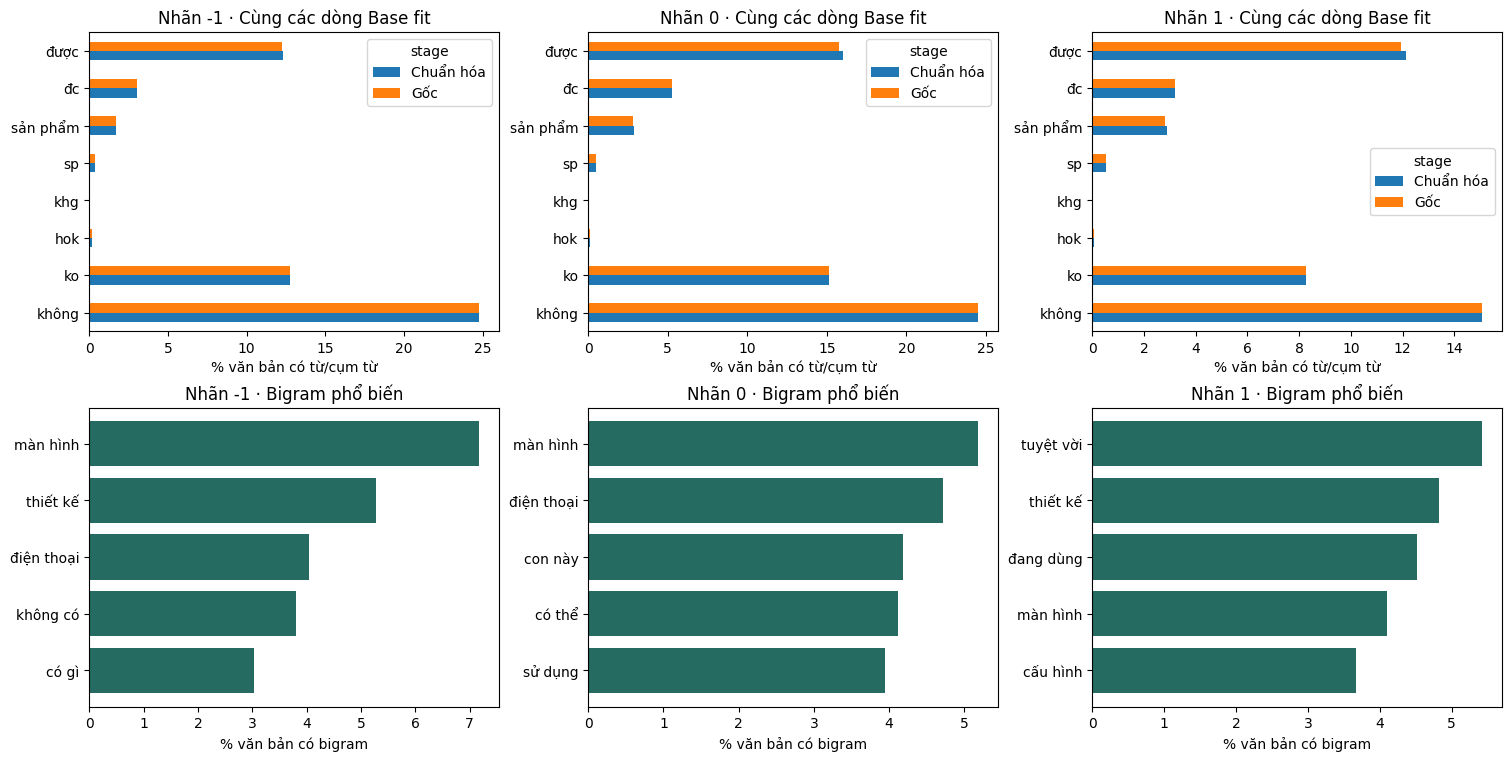

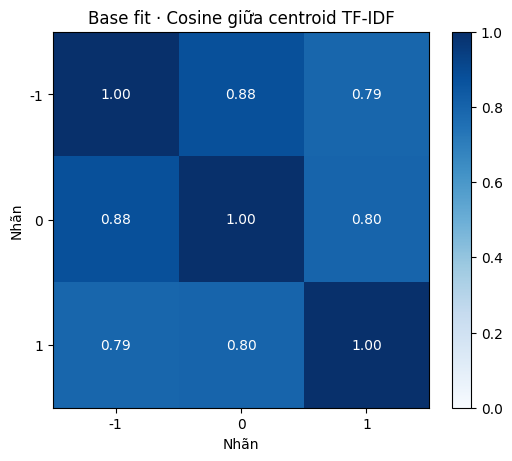

Cặp ngoài đường chéo có cosine lớn nhất: -1 / 0 (0.877).


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

base_fit = training["Base"]
signals = ("không", "ko", "hok", "khg", "sp", "sản phẩm", "đc", "được")
signal_rows = []
for label, frame in base_fit.groupby("label"):
    for stage, field in (("Gốc", "text"), ("Chuẩn hóa", "text_clean")):
        for term in signals:
            pattern = r"(?<!\w)" + re.escape(term) + r"(?!\w)"
            share = frame[field].str.casefold().str.contains(pattern, regex=True).mean()
            signal_rows.append((label, stage, term, 100 * share))
signal_rates = pd.DataFrame(signal_rows, columns=["label", "stage", "term", "document_pct"])
signal_rates.to_csv(eda_dir / "lexical_signals.csv", index=False)

def make_tfidf_vectorizer():
    return TfidfVectorizer(
        max_features=20000, ngram_range=(1, 2), sublinear_tf=True, lowercase=False,
        token_pattern=POLICY['tfidf']['token_pattern'], dtype=np.float32,
    )

def plot_class_vocabulary(frame):
    vectorizer = make_tfidf_vectorizer()
    matrix = vectorizer.fit_transform(frame["text_tfidf"])
    terms = vectorizer.get_feature_names_out()
    bigram_cols = np.flatnonzero(np.char.find(terms.astype(str), " ") >= 0)
    bigram_rows = []
    centroids = []
    for label in LABELS:
        sparse_rows = matrix[frame["label"].to_numpy() == label]
        centroids.append(np.asarray(sparse_rows.mean(axis=0)).ravel())
        rates = np.asarray(sparse_rows[:, bigram_cols].getnnz(axis=0)).ravel() / sparse_rows.shape[0]
        shown = sorted(np.flatnonzero(rates > 0), key=lambda index: (-rates[index], terms[bigram_cols[index]]))[:5]
        bigram_rows.extend((label, terms[bigram_cols[i]], 100 * rates[i]) for i in shown)

    bigrams = pd.DataFrame(bigram_rows, columns=["label", "bigram", "document_pct"])
    bigrams.to_csv(eda_dir / "top_bigrams.csv", index=False)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
    for col, label in enumerate(LABELS):
        values = signal_rates[signal_rates.label == label].pivot(index="term", columns="stage", values="document_pct")
        values.reindex(signals).plot.barh(ax=axes[0, col])
        axes[0, col].set(title=f"Nhãn {label} · Cùng các dòng Base fit", xlabel="% văn bản có từ/cụm từ", ylabel="")
        top = bigrams[bigrams.label == label].iloc[::-1]
        ax = axes[1, col]
        if top.empty:
            ax.text(0.5, 0.5, "Không có bigram trong vocabulary", transform=ax.transAxes, ha="center")
        else:
            ax.barh(top.bigram, top.document_pct, color="#256b62")
        ax.set(xlabel="% văn bản có bigram", title=f"Nhãn {label} · Bigram phổ biến")
    save_text_figure(fig, "eda-lexical.png")

    similarity = cosine_similarity(np.stack(centroids))
    pd.DataFrame(similarity, index=LABELS, columns=LABELS).to_csv(eda_dir / "class_cosine.csv")
    fig, ax = plt.subplots(figsize=(5.5, 4.5), constrained_layout=True)
    image = ax.imshow(similarity, vmin=0, vmax=1, cmap="Blues")
    ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS,
           xlabel="Nhãn", ylabel="Nhãn", title="Base fit · Cosine giữa centroid TF-IDF")
    for row, col in np.ndindex(similarity.shape):
        value = similarity[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color="white" if value > .6 else "black")
    fig.colorbar(image, ax=ax)
    save_text_figure(fig, "eda-class-similarity.png")
    pairs = [(similarity[i, j], LABELS[i], LABELS[j]) for i in range(3) for j in range(i + 1, 3)]
    score, left, right = max(pairs)
    print(f"Cặp ngoài đường chéo có cosine lớn nhất: {left} / {right} ({score:.3f}).")

plot_class_vocabulary(base_fit)


## 4.3. Chiều dài đầu vào và manifest

Đếm BPE gồm token đặc biệt; tỷ lệ vượt ngưỡng cho biết khả năng mất nội dung. Lưu hash nguồn, audit và danh sách sample_id để kiểm chứng mọi lượt dùng chung test.


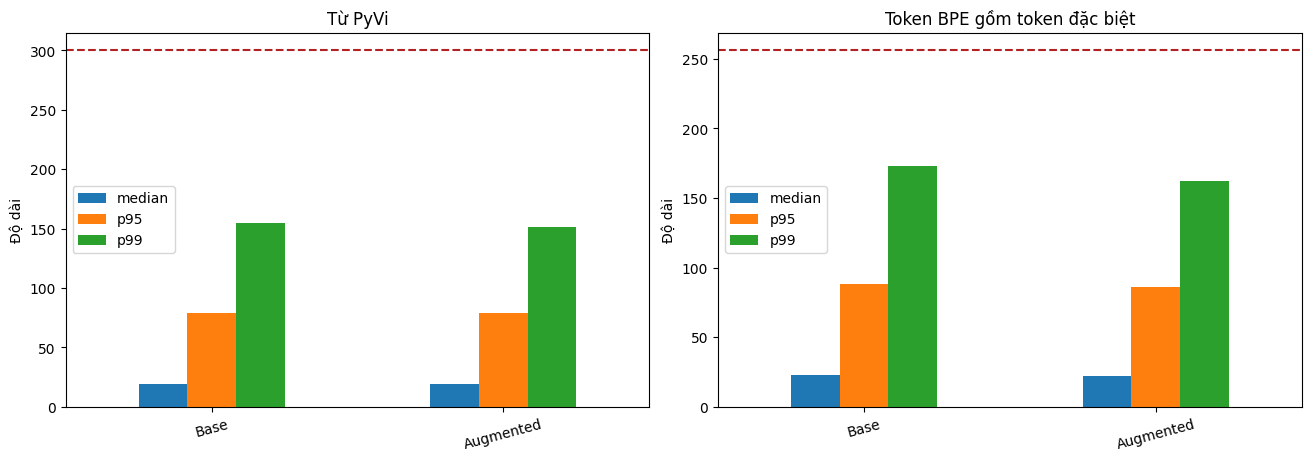

,limit,median,p95,p99,over_limit,over_limit_pct
split,,,,,,
Base,300,19.0,79.0,154.59,16,0.32
Augmented,300,19.0,79.0,151.23,27,0.27


,limit,median,p95,p99,over_limit,over_limit_pct
split,,,,,,
Base,256,23.0,88.0,172.95,22,0.44
Augmented,256,22.0,86.0,162.00,36,0.36


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, table, title in zip(axes, (word_lengths, bpe_lengths), ('Từ PyVi', 'Token BPE gồm token đặc biệt')):
    table[['median', 'p95', 'p99']].plot.bar(ax=ax, rot=15)
    ax.axhline(table['limit'].iloc[0], color='firebrick', linestyle='--')
    ax.set(title=title, ylabel='Độ dài', xlabel='')
save_text_figure(fig, 'eda-tokenizers.png')
display(word_lengths.round(2))
display(bpe_lengths.round(2))
word_lengths.to_csv(eda_dir / 'word_lengths.csv')
bpe_lengths.to_csv(eda_dir / 'bpe_lengths.csv')
audit.to_csv(RUN_DIR / 'data_audit.csv')

if SMOKE_TEST:
    def small(frame, count):
        return pd.concat([g.sample(min(count, len(g)), random_state=SEED) for _, g in frame.groupby('label')]).sort_values('sample_id').reset_index(drop=True)
    training = {name: small(frame, 8) for name, frame in training.items()}
    test = small(test, 2)
    validation = small(validation, 2) if validation is not None else None
partitions = {**training, 'Test': test}
if validation is not None:
    partitions['Validation'] = validation
manifest = pd.concat([frame.assign(split=name)[['split', 'sample_id', 'label', 'clean_key']] for name, frame in partitions.items()], ignore_index=True)
manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
fit_mode = 'grouped_validation' if validation is not None else 'fixed_configuration'
run_metadata = {'run_id': RUN_ID, 'smoke_test': SMOKE_TEST, 'seed': SEED, 'dataset': DATASET_HANDLE,
    'fit_mode': fit_mode, 'labels': LABELS, 'architectures': ARCHITECTURES,
    'sample_counts': {name: len(frame) for name, frame in partitions.items()},
    'sources': {name: {'filename': path.name, 'sha256': sha256_file(path)} for name, path in paths.items()},
    'epochs': {'neural': NEURAL_EPOCHS, 'phobert': PHOBERT_EPOCHS},
    'timing_definition': 'Fit preprocessor + model initialization + training/validation; excludes shared Word2Vec loading and test inference.',
    'phobert_effective_batch': PHOBERT_BATCH_SIZE * PHOBERT_ACCUMULATION,
    'manifest_sha256': sha256_file(RUN_DIR / 'split_manifest.csv')}
if lineage_path is not None:
    run_metadata['lineage_sha256'] = sha256_file(lineage_path)
write_json(RUN_DIR / 'run.json', run_metadata)

run_metadata['preprocessing'] = POLICY
write_json(RUN_DIR / 'run.json', run_metadata)


# (5) Xây dựng ba pipeline

SVD tối đa 300 thành phần, giới hạn theo số mẫu/đặc trưng fit; GRU một chiều hidden 64, batch 64, nhận độ dài thật; PhoBERT-base-v2 giữ effective batch 32. TF-IDF/SVD và vocabulary chỉ fit trên từng tập train.


In [ ]:
class WordSequences(TorchDataset):
    def __init__(self, frame, vocabulary):
        self.tokens = []
        self.lengths = []
        self.labels = (frame.label.to_numpy() + 1).astype(np.int64)
        for text in frame.words:
            sequence = [vocabulary.get(word, 1) for word in text.split()[:W2V_MAX_LENGTH]] or [1]
            self.lengths.append(len(sequence))
            self.tokens.append(sequence + [0] * (W2V_MAX_LENGTH - len(sequence)))
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return {'tokens': torch.tensor(self.tokens[index]), 'lengths': torch.tensor(self.lengths[index]),
                'labels': torch.tensor(self.labels[index])}

class PhoBERTInputs(TorchDataset):
    def __init__(self, frame):
        self.encoded = phobert_tokenizer(frame.phobert_words.tolist(), truncation=True, max_length=PHOBERT_MAX_LENGTH)
        self.labels = (frame.label.to_numpy() + 1).astype(np.int64)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return {**{key: values[index] for key, values in self.encoded.items()}, 'labels': int(self.labels[index])}

def independent_embedding(weights):
    return nn.Embedding.from_pretrained(weights.detach().clone(), freeze=False, padding_idx=0)

class CBOWGRU(nn.Module):
    def __init__(self, weights):
        super().__init__()
        self.embedding = independent_embedding(weights)
        self.gru = nn.GRU(weights.shape[1], 64, batch_first=True)
        self.fc = nn.Sequential(nn.Dropout(.5), nn.Linear(64, 3))
    def forward(self, tokens, lengths):
        embedded = self.embedding(tokens)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        return self.fc(hidden[-1])

WORD_MODELS = {'CBOW + GRU': CBOWGRU}

def build_text_model(architecture, embeddings=None):
    if architecture == 'TF-IDF + SVD + LinearSVC':
        return LinearSVC(C=1., random_state=SEED, max_iter=2000)
    if architecture in WORD_MODELS:
        return WORD_MODELS[architecture](embeddings)
    if architecture == 'PhoBERT-base-v2':
        from transformers import AutoModelForSequenceClassification
        return AutoModelForSequenceClassification.from_pretrained(PHOBERT_MODEL, num_labels=3)
    raise ValueError(f'Kiến trúc không được hỗ trợ: {architecture}')

def build_vocabulary(frame):
    counts = Counter(word for text in frame.words for word in text.split())
    return {word: index for index, (word, _) in enumerate(counts.most_common(MAX_VOCAB_SIZE - 2), start=2)}

def make_embeddings(vocabulary, word_vectors):
    rng = np.random.default_rng(SEED)
    matrix = rng.normal(0, .5, (len(vocabulary) + 2, word_vectors.vector_size)).astype(np.float32)
    matrix[0] = 0
    for word, index in vocabulary.items():
        if word in word_vectors:
            matrix[index] = word_vectors[word]
    return torch.from_numpy(matrix)

def neural_logits(model, architecture, batch):
    if architecture == 'PhoBERT-base-v2':
        return model(**{key: value.to(DEVICE) for key, value in batch.items() if key != 'labels'}).logits
    return model(batch['tokens'].to(DEVICE), batch['lengths'].to(DEVICE))

def make_neural_dataset(architecture, frame, preprocessor=None):
    if architecture == 'PhoBERT-base-v2':
        return PhoBERTInputs(frame)
    return WordSequences(frame, preprocessor)

def make_text_loader(dataset, architecture, shuffle=False):
    from transformers import DataCollatorWithPadding
    batch_size = PHOBERT_BATCH_SIZE if architecture == 'PhoBERT-base-v2' else 64
    collator = DataCollatorWithPadding(phobert_tokenizer) if architecture == 'PhoBERT-base-v2' else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, collate_fn=collator,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

def evaluate_text_neural(model, architecture, loader):
    model.eval()
    loss_sum, count = 0., 0
    probabilities, truth = [], []
    for batch in loader:
        labels = batch['labels'].to(DEVICE)
        logits = neural_logits(model, architecture, batch)
        loss_sum += F.cross_entropy(logits, labels, reduction='sum').item()
        count += len(labels)
        truth.extend(labels.cpu().tolist())
        probabilities.append(logits.softmax(1).cpu().numpy())
    probabilities = np.concatenate(probabilities)
    prediction = probabilities.argmax(1)
    return {'loss': loss_sum / count, 'accuracy': float(accuracy_score(truth, prediction)),
            'macro_f1': float(f1_score(truth, prediction, labels=[0, 1, 2], average='macro', zero_division=0))}, probabilities

def verify_word_models():
    # Kiểm tra chính hành vi: các lượt độc lập và padding không đổi logits.
    weights = torch.randn(8, 6)
    weights[0] = 0
    for constructor in WORD_MODELS.values():
        left, right = constructor(weights).eval(), constructor(weights).eval()
        assert left.embedding.weight.data_ptr() != right.embedding.weight.data_ptr()
        assert left.embedding.weight.data_ptr() != weights.data_ptr()
        before = right.embedding.weight.detach().clone()
        with torch.no_grad():
            left.embedding.weight[2].add_(1)
        torch.testing.assert_close(right.embedding.weight, before)
        lengths = torch.tensor([3, 5])
        x = torch.tensor([[2, 3, 4, 0, 0], [2, 3, 4, 5, 6]])
        with torch.no_grad():
            torch.testing.assert_close(left(x, lengths), left(F.pad(x, (0, 4)), lengths), atol=1e-6, rtol=1e-5)
    print('Đã kiểm tra embedding độc lập và bất biến theo padding cho GRU.')

verify_word_models()

Đã kiểm tra embedding độc lập và bất biến theo padding cho GRU.


# (6) Huấn luyện sáu cấu hình

Chạy tuần tự ba pipeline trên Base/Augmented, lưu checkpoint và history. Thiếu lineage: GRU 4 epoch, PhoBERT 3 epoch; có lineage chọn validation macro-F1. Smoke 1 epoch mỗi neural.


In [ ]:
from transformers import AutoModelForSequenceClassification, get_cosine_schedule_with_warmup

from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import Pipeline

experiments = {}


def experiment_directory(architecture, dataset):
    slug = re.sub(r'[^a-z0-9]+', '-', architecture.lower()).strip('-')
    directory = RUN_DIR / 'models' / slug / dataset.lower()
    directory.mkdir(parents=True, exist_ok=True)
    return directory


def train_text_neural(model, architecture, frame, preprocessor, directory):
    model.to(DEVICE)
    epochs = PHOBERT_EPOCHS if architecture == 'PhoBERT-base-v2' else NEURAL_EPOCHS
    train_dataset = make_neural_dataset(architecture, frame, preprocessor)
    train_loader = make_text_loader(train_dataset, architecture, shuffle=True)
    train_evaluation = make_text_loader(train_dataset, architecture)
    val_loader = make_text_loader(make_neural_dataset(architecture, validation, preprocessor), architecture) if validation is not None else None
    is_phobert = architecture == 'PhoBERT-base-v2'
    optimizer = (torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=.01) if is_phobert
                 else torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5))
    accumulation = PHOBERT_ACCUMULATION if is_phobert else 1
    total_steps = epochs * math.ceil(len(train_loader) / accumulation)
    scheduler = get_cosine_schedule_with_warmup(optimizer, min(100, max(0, total_steps - 1)), total_steps) if is_phobert else None
    scaler = torch.amp.GradScaler('cuda', enabled=is_phobert and DEVICE.type == 'cuda')
    history, best_score, bad_epochs, selected_epoch = [], -1., 0, 0
    checkpoint = directory / 'best.pt'
    for epoch in range(epochs):
        model.train()
        total_loss, sample_count = 0., 0
        optimizer.zero_grad(set_to_none=True)
        for index, batch in enumerate(train_loader):
            labels = batch['labels'].to(DEVICE)
            start = (index // accumulation) * accumulation * train_loader.batch_size
            window_samples = min(accumulation * train_loader.batch_size, len(train_dataset) - start)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=scaler.is_enabled()):
                logits = neural_logits(model, architecture, batch)
                loss = F.cross_entropy(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Loss không hữu hạn: {architecture}, epoch {epoch + 1}')
            scaler.scale(loss * len(labels) / window_samples).backward()
            if (index + 1) % accumulation == 0 or index + 1 == len(train_loader):
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.)
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None and scaler.get_scale() >= old_scale:
                    scheduler.step()
                optimizer.zero_grad(set_to_none=True)
            total_loss += loss.item() * len(labels)
            sample_count += len(labels)
        train_values, _ = evaluate_text_neural(model, architecture, train_evaluation)
        row = {'epoch': epoch + 1, 'train_loss': total_loss / sample_count,
               'train_accuracy': train_values['accuracy'], 'train_macro_f1': train_values['macro_f1'],
               'train_eval_loss': train_values['loss']}
        if val_loader is not None:
            val_values, _ = evaluate_text_neural(model, architecture, val_loader)
            row.update({f'val_{key}': value for key, value in val_values.items()})
            improved = val_values['macro_f1'] > best_score
            if improved:
                best_score, bad_epochs, selected_epoch = val_values['macro_f1'], 0, epoch + 1
                torch.save(model.state_dict(), checkpoint)
            else:
                bad_epochs += 1
        history.append(row)
        pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
        print(f'{architecture} | epoch {epoch + 1}/{epochs} | loss={row["train_loss"]:.4f} | train F1={row["train_macro_f1"]:.4f}'
              + (f' | val F1={row["val_macro_f1"]:.4f}' if val_loader is not None else ' | không có validation'), flush=True)
        if val_loader is not None and bad_epochs >= (2 if is_phobert else 4):
            print('Early stopping theo validation macro-F1.', flush=True)
            break
    if val_loader is None:
        selected_epoch = len(history)
        torch.save(model.state_dict(), checkpoint)
    else:
        model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    if is_phobert:
        model.save_pretrained(directory / 'pretrained')
        phobert_tokenizer.save_pretrained(directory / 'pretrained')
        checkpoint.unlink()  # save_pretrained đã lưu cùng trọng số, tránh bản sao lớn.
    del optimizer, scheduler, scaler, train_loader, train_evaluation, val_loader
    return {'history': history, 'selected_epoch': selected_epoch,
            'selection': 'validation_macro_f1' if validation is not None else 'fixed_final_epoch'}


if RUN_TRAINING:
    from gensim.models import KeyedVectors
    vector_path = Path(WORD2VEC_FILE) if WORD2VEC_FILE is not None else data_root / 'vi-model-CBOW.bin'
    if not vector_path.is_file():
        raise FileNotFoundError(f'Thiếu vector CBOW: {vector_path}')
    run_metadata['word2vec'] = {'file': vector_path.name, 'sha256': sha256_file(vector_path)}
    write_json(RUN_DIR / 'run.json', run_metadata)
    vectors = None
    for architecture in ARCHITECTURES:
        if architecture in WORD_MODELS and vectors is None:
            vectors = KeyedVectors.load_word2vec_format(str(vector_path), binary=True)
        if architecture == 'PhoBERT-base-v2':
            del vectors
            vectors = None
            release_memory()
        for dataset_name, frame in training.items():
            seed_everything()
            directory = experiment_directory(architecture, dataset_name)
            print(f'\nHuấn luyện {architecture} / {dataset_name}: {len(frame):,} mẫu', flush=True)
            started = time.perf_counter()
            preprocessor = None
            if architecture.startswith('TF-IDF'):
                vectorizer = make_tfidf_vectorizer()
                matrix = vectorizer.fit_transform(frame.text_tfidf)
                components = min(300, matrix.shape[0] - 1, matrix.shape[1] - 1)
                if components < 1: raise ValueError('Không đủ dữ liệu fit SVD')
                reducer = TruncatedSVD(n_components=components, random_state=SEED)
                reducer.fit(matrix)
                preprocessor = Pipeline([('tfidf', vectorizer), ('svd', reducer)])
                joblib.dump(preprocessor, directory / 'vectorizer.joblib')
                write_json(directory / 'svd_config.json', {'max_components':300,'actual_components':components,'fit_samples':matrix.shape[0],'tfidf_features':matrix.shape[1],'seed':SEED})
            if architecture == 'TF-IDF + SVD + LinearSVC':
                model = build_text_model(architecture)
                model.fit(preprocessor.transform(frame.text_tfidf), frame.label.to_numpy() + 1)
                joblib.dump(model, directory / 'classifier.joblib')
                summary = {'history': [], 'selected_epoch': None, 'selection': 'single_fit',
                           'parameters': int(model.coef_.size + model.intercept_.size)}
            else:
                if architecture in WORD_MODELS:
                    preprocessor = build_vocabulary(frame)
                    write_json(directory / 'vocabulary.json', preprocessor)
                    weights = make_embeddings(preprocessor, vectors)
                    model = build_text_model(architecture, weights)
                    del weights
                else:
                    model = build_text_model(architecture)
                parameter_count = sum(p.numel() for p in model.parameters())
                summary = train_text_neural(model, architecture, frame, preprocessor, directory)
                summary['parameters'] = parameter_count
            summary.update(architecture=architecture, dataset=dataset_name, train_seconds=time.perf_counter() - started,
                           fit_mode=fit_mode, fit_rows=len(frame), directory=str(directory))
            probe_frame = frame.head(2)
            if architecture == 'TF-IDF + SVD + LinearSVC':
                probe = model.decision_function(preprocessor.transform(probe_frame.text_tfidf))
            else:
                probe_loader = make_text_loader(make_neural_dataset(architecture, probe_frame, preprocessor), architecture)
                _, probe = evaluate_text_neural(model, architecture, probe_loader)
                del probe_loader
            np.save(directory / 'reload_probe.npy', probe)
            write_json(directory / 'training_summary.json', summary)
            experiments[(architecture, dataset_name)] = summary
            del model, preprocessor
            release_memory()
    assert len(experiments) == 6
else:
    print('RUN_TRAINING=False: chỉ xuất EDA; các phần sau không tạo kết quả mô hình.')



Huấn luyện TF-IDF + SVD + LinearSVC / Base: 24 mẫu



Huấn luyện TF-IDF + SVD + LinearSVC / Augmented: 24 mẫu



Huấn luyện CBOW + GRU / Base: 24 mẫu


RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

# (7) Vẽ đường học

Loss, accuracy và macro-F1 lấy từ từng epoch thật. Accuracy/F1 train được đo ở chế độ eval; loss train là trung bình có trọng số số mẫu trong lúc cập nhật. Khi không có validation, hình chỉ vẽ train. LinearSVC không có lịch sử epoch tương đương neural.


In [ ]:
if RUN_TRAINING:
    for (architecture, dataset_name), result in experiments.items():
        if not result['history']:
            print(architecture, dataset_name, ': fit một lần, không có đường học theo epoch.')
            continue
        table = pd.DataFrame(result['history'])
        fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
        for ax, metric in zip(axes, ('loss', 'accuracy', 'macro_f1')):
            ax.plot(table.epoch, table[f'train_{metric}'], marker='.', label='train')
            if f'val_{metric}' in table:
                ax.plot(table.epoch, table[f'val_{metric}'], marker='.', label='validation')
            ax.axvline(result['selected_epoch'], color='gray', linestyle='--', label='checkpoint chọn')
            ax.set(xlabel='Epoch', ylabel=metric)
            ax.legend()
        fig.suptitle(f'{architecture} · {dataset_name} · {fit_mode}')
        fig.savefig(Path(result['directory']) / 'learning_curves.png', dpi=140, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print(f"Caption: {architecture}/{dataset_name}, checkpoint epoch {result['selected_epoch']}; "
              + ('chọn theo validation macro-F1.' if validation is not None else 'epoch cuối cố định, không có validation.'))


TF-IDF + SVD + LinearSVC Base : fit một lần, không có đường học theo epoch.
TF-IDF + SVD + LinearSVC Augmented : fit một lần, không có đường học theo epoch.


# (8) Đánh giá mô hình

Nạp lại từng checkpoint và đánh giá đúng cùng sample_id test. Nhãn nguồn vẫn là −1/0/+1. Neural lưu xác suất; LinearSVC lưu margin, không diễn giải margin thành xác suất.


In [ ]:
def load_text_experiment(architecture, result):
    directory = Path(result['directory'])
    preprocessor = None
    if architecture.startswith('TF-IDF'):
        preprocessor = joblib.load(directory / 'vectorizer.joblib')
    if architecture == 'TF-IDF + SVD + LinearSVC':
        return joblib.load(directory / 'classifier.joblib'), preprocessor
    if architecture == 'PhoBERT-base-v2':
        model = AutoModelForSequenceClassification.from_pretrained(directory / 'pretrained')
    else:
        state = torch.load(directory / 'best.pt', map_location='cpu', weights_only=True)
        preprocessor = json.loads((directory / 'vocabulary.json').read_text())
        model = WORD_MODELS[architecture](state['embedding.weight'])
        model.load_state_dict(state)
    return model.to(DEVICE).eval(), preprocessor


def score_frame(model, architecture, frame, preprocessor):
    if architecture == 'TF-IDF + SVD + LinearSVC':
        scores = model.decision_function(preprocessor.transform(frame.text_tfidf))
        return model.classes_[scores.argmax(1)] - 1, scores, 'margin'
    loader = make_text_loader(make_neural_dataset(architecture, frame, preprocessor), architecture)
    _, scores = evaluate_text_neural(model, architecture, loader)
    return scores.argmax(1) - 1, scores, 'probability'


results, predictions, per_class_records = [], [], []
if RUN_TRAINING:
    expected = {(architecture, name) for architecture in ARCHITECTURES for name in ('Base', 'Augmented')}
    assert set(experiments) == expected
    fig, axes = plt.subplots(3, 2, figsize=(11, 12), constrained_layout=True)
    for index, ((architecture, dataset_name), training_result) in enumerate(experiments.items()):
        model, preprocessor = load_text_experiment(architecture, training_result)
        directory = Path(training_result['directory'])
        probe_frame = training[dataset_name].head(2)
        _, reloaded_probe, _ = score_frame(model, architecture, probe_frame, preprocessor)
        np.testing.assert_allclose(reloaded_probe, np.load(directory / 'reload_probe.npy'), atol=1e-5, rtol=1e-4)
        started = time.perf_counter()
        predicted, scores, score_type = score_frame(model, architecture, test, preprocessor)
        truth = test.label.to_numpy()
        report = classification_report(truth, predicted, labels=LABELS, target_names=CLASS_NAMES,
                                       output_dict=True, zero_division=0)
        matrix = confusion_matrix(truth, predicted, labels=LABELS)
        summary = {'architecture': architecture, 'dataset': dataset_name,
                   'accuracy': float(accuracy_score(truth, predicted)),
                   'balanced_accuracy': float(balanced_accuracy_score(truth, predicted)),
                   'macro_precision': float(report['macro avg']['precision']),
                   'macro_recall': float(report['macro avg']['recall']),
                   'macro_f1': float(report['macro avg']['f1-score']),
                   'weighted_f1': float(report['weighted avg']['f1-score']),
                   'mcc': float(matthews_corrcoef(truth, predicted)),
                   'polarity_reversal_rate': float(np.mean(predicted[truth != 0] == -truth[truth != 0])),
                   'support': len(test), 'parameters': training_result['parameters'],
                   'train_seconds': training_result['train_seconds'],
                   'inference_seconds': time.perf_counter() - started}
        assert int(matrix.sum()) == len(test)
        assert np.isclose(matrix.trace() / matrix.sum(), summary['accuracy'])
        records = test[['sample_id', 'text', 'text_clean', 'label']].copy().rename(columns={'label': 'true_label'})
        records.insert(0, 'architecture', architecture)
        records.insert(1, 'dataset', dataset_name)
        records['predicted_label'] = predicted
        records['score_type'] = score_type
        records['score'] = scores.max(1)
        for j, label in enumerate(LABELS):
            records[f'score_{label}'] = scores[:, j]
        records.to_csv(directory / 'test_predictions.csv', index=False)
        write_json(directory / 'metrics.json', summary)
        write_json(directory / 'classification_report.json', report)
        pd.DataFrame(matrix, index=LABELS, columns=LABELS).to_csv(directory / 'confusion_counts.csv')
        for label, name in zip(LABELS, CLASS_NAMES):
            per_class_records.append({'architecture': architecture, 'dataset': dataset_name, 'label': label,
                                      'class_name': name, **report[name]})
        results.append(summary)
        predictions.append(records)
        ax = axes.flat[index]
        ax.imshow(matrix, cmap='Blues', vmin=0, vmax=int(test.label.value_counts().max()))
        ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS,
               xlabel='Dự đoán', ylabel='Nhãn thật', title=f'{architecture}\n{dataset_name}')
        for row, column in np.ndindex(matrix.shape):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() * .55 else 'black')
        print(architecture, dataset_name, {key: round(summary[key], 4) for key in ['accuracy', 'macro_f1']}, flush=True)
        display(pd.DataFrame(report).T.round(4))
        del model, preprocessor
        release_memory()
    fig.savefig(RUN_DIR / 'confusion-matrices.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    prediction_table = pd.concat(predictions, ignore_index=True)
    prediction_table.to_csv(RUN_DIR / 'predictions.csv', index=False)
    pd.DataFrame(per_class_records).to_csv(RUN_DIR / 'per_class_metrics.csv', index=False)
    write_json(RUN_DIR / 'results.json', {'run': run_metadata, 'results': results})


AssertionError: 

# (9) So sánh mô hình

Đối chiếu đủ 6 cấu hình, ưu tiên macro-F1; chênh lệch Augmented − Base dùng điểm phần trăm. Thời gian được đo trên cùng phiên, gồm chi phí validation của từng mô hình. Một seed chưa chứng minh khác biệt có ý nghĩa thống kê.


In [ ]:
if RUN_TRAINING:
    summary = pd.DataFrame(results)
    summary.to_csv(RUN_DIR / 'summary.csv', index=False)
    display(summary.sort_values('macro_f1', ascending=False).round(4))
    comparison = summary.pivot(index='architecture', columns='dataset', values='macro_f1').reindex(ARCHITECTURES)
    comparison['delta_pp'] = 100 * (comparison.Augmented - comparison.Base)
    comparison.to_csv(RUN_DIR / 'augmentation_delta.csv')
    display(comparison.round(4))
    ax = comparison[['Base', 'Augmented']].plot.barh(figsize=(10, 5), xlim=(0, 1))
    ax.set(xlabel='Test macro-F1', ylabel='', title='Ba pipeline · cùng test')
    ax.figure.tight_layout()
    ax.figure.savefig(RUN_DIR / 'model-comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(ax.figure)
    costs = summary[['architecture', 'dataset', 'parameters', 'train_seconds', 'inference_seconds']]
    display(costs.round(2))
    print('Caption: Δ macro-F1 (Augmented − Base), điểm phần trăm:')
    for architecture, row in comparison.iterrows():
        print(f'{architecture}: {row.delta_pp:+.2f}')


KeyError: 'macro_f1'

# (10) Phân tích mẫu sai

Xem câu gốc, câu chuẩn hóa, nhãn thật và dự đoán từ CSV. Nhóm theo cặp nhãn nhầm để tìm trường hợp cần đọc kỹ; không tự gán cơ chế lỗi ngôn ngữ khi chưa kiểm tra nội dung.


In [ ]:
if RUN_TRAINING:
    mistakes = prediction_table.loc[prediction_table.true_label != prediction_table.predicted_label].copy()
    mistakes.to_csv(RUN_DIR / 'errors.csv', index=False)
    error_pairs = mistakes.groupby(['architecture', 'dataset', 'true_label', 'predicted_label']).size().rename('count').reset_index()
    error_pairs.to_csv(RUN_DIR / 'error_pairs.csv', index=False)
    for architecture in ARCHITECTURES:
        selected = mistakes.loc[(mistakes.architecture == architecture) & (mistakes.dataset == 'Augmented')]
        print('\n', architecture, 'Augmented:', len(selected), '/', len(test), 'câu sai')
        if selected.empty:
            print('Không có câu sai trong test của lần chạy này.')
            continue
        display(selected.groupby(['true_label', 'predicted_label']).size().rename('count').reset_index())
        display(selected.sort_values(['score', 'sample_id'], ascending=[False, True])[
            ['sample_id', 'text', 'text_clean', 'true_label', 'predicted_label', 'score_type', 'score']].head(6))
    print('Câu sai được trích từ dự đoán thật; cần đọc ngữ cảnh trước khi gọi đó là phủ định, mỉa mai hay nhãn mơ hồ.')


NameError: name 'prediction_table' is not defined

# (11) Giải thích và kết luận

SVC: quy chiếu trọng số qua các thành phần SVD về đặc trưng TF-IDF; kiểm tra tổng đóng góp và intercept khớp margin. PhoBERT Augmented: bỏ từ trong tối đa hai câu đúng/hai câu sai; kiểm tra trọng số không đổi. Kết luận lấy từ kết quả vừa chạy.


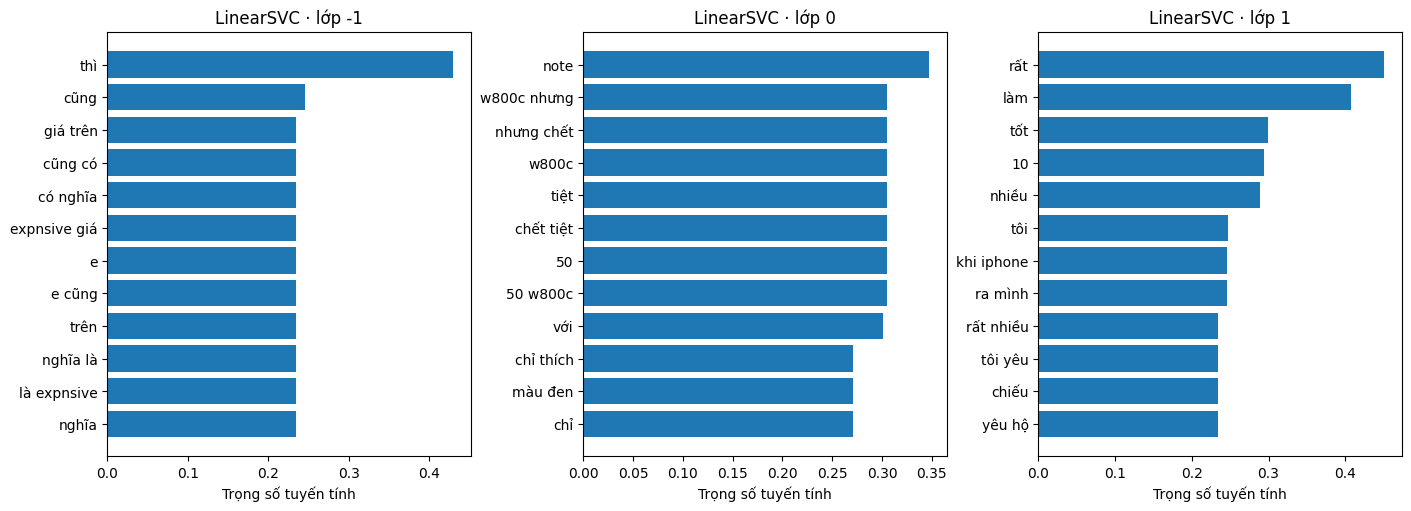

,term,contribution
3,chưa,-0.035283
2,giờ,-0.031163
1,4,-0.025898
0,mua,-0.001513
4,note,0.149042


Câu LinearSVC: test-1041 Đùa chứ giờ còn chưa mua nổi note 4?? | lớp dự đoán: 0


KeyError: ('PhoBERT-base-v2', 'Augmented')

In [ ]:
if RUN_TRAINING:
    explanation_dir = RUN_DIR / 'explanations'
    explanation_dir.mkdir(exist_ok=True)
    svc_result = experiments[('TF-IDF + SVD + LinearSVC', 'Augmented')]
    svc, vectorizer = load_text_experiment('TF-IDF + SVD + LinearSVC', svc_result)
    reducer = vectorizer.named_steps['svd']
    vectorizer = vectorizer.named_steps['tfidf']
    projected_coefficients = svc.coef_ @ reducer.components_
    terms = vectorizer.get_feature_names_out()
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True)
    for label, ax, weights in zip(LABELS, axes, projected_coefficients):
        indices = np.argsort(weights)[-12:]
        ax.barh(terms[indices], weights[indices])
        ax.set(title=f'LinearSVC · lớp {label}', xlabel='Trọng số tuyến tính')
        rows.extend({'label': label, 'term': str(terms[i]), 'weight': float(weights[i])} for i in indices)
    fig.savefig(explanation_dir / 'svc-weights.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    pd.DataFrame(rows).to_csv(explanation_dir / 'svc_weights.csv', index=False)
    sample = test.sort_values('sample_id').iloc[0]
    x = vectorizer.transform([sample.text_tfidf])
    scores = svc.decision_function(reducer.transform(x))[0]
    target = int(scores.argmax())
    contribution = np.asarray(x.multiply(projected_coefficients[target]).toarray()).ravel()
    assert np.isclose(contribution.sum() + svc.intercept_[target], scores[target])
    nonzero = np.flatnonzero(contribution)
    indices = nonzero[np.argsort(np.abs(contribution[nonzero]))[-12:]]
    display(pd.DataFrame({'term': terms[indices], 'contribution': contribution[indices]}).sort_values('contribution'))
    print('Câu LinearSVC:', sample.sample_id, sample.text, '| lớp dự đoán:', target - 1)
    del svc, vectorizer

    model, _ = load_text_experiment('PhoBERT-base-v2', experiments[('PhoBERT-base-v2', 'Augmented')])
    model.eval()
    def model_digest(model):
        digest = hashlib.sha256()
        for value in model.state_dict().values():
            digest.update(value.detach().cpu().contiguous().numpy().tobytes())
        return digest.hexdigest()
    before_digest = model_digest(model)

    @torch.inference_mode()
    def phobert_probabilities(texts):
        output = []
        for start in range(0, len(texts), PHOBERT_BATCH_SIZE):
            encoded = phobert_tokenizer(texts[start:start + PHOBERT_BATCH_SIZE], padding=True, truncation=True,
                                        max_length=PHOBERT_MAX_LENGTH, return_tensors='pt').to(DEVICE)
            output.append(model(**encoded).logits.softmax(1).cpu().numpy())
        return np.concatenate(output)

    candidates = prediction_table.loc[(prediction_table.architecture == 'PhoBERT-base-v2') &
                                     (prediction_table.dataset == 'Augmented')].copy()
    candidates = candidates.merge(test[['sample_id', 'phobert_words']], on='sample_id', validate='one_to_one')
    candidates = candidates[candidates.phobert_words.str.split().str.len().between(1, 32)]
    candidates = candidates[candidates.phobert_words.map(lambda text: len(phobert_tokenizer.encode(text)) <= PHOBERT_MAX_LENGTH)]
    chosen = pd.concat([candidates.loc[(candidates.true_label == candidates.predicted_label) == correct]
                        .sort_values('sample_id').head(2) for correct in [True, False]])
    effects = []
    for row in chosen.itertuples():
        words = row.phobert_words.split()
        variants = [row.phobert_words] + [' '.join(words[:i] + words[i + 1:]) for i in range(len(words))]
        probabilities = phobert_probabilities(variants)
        target = int(probabilities[0].argmax())
        assert target - 1 == row.predicted_label
        delta = probabilities[0, target] - probabilities[1:, target]
        fig, ax = plt.subplots(figsize=(9, max(3, len(words) * .22)))
        ax.barh(range(len(words)), delta, color=['#287764' if value >= 0 else '#a74d35' for value in delta])
        ax.set(yticks=range(len(words)), yticklabels=words, xlabel='P(lớp dự đoán ban đầu) − P(sau bỏ từ)',
               title=f'{row.sample_id}: thật {row.true_label}, dự đoán {row.predicted_label}')
        fig.tight_layout()
        fig.savefig(explanation_dir / f'phobert-{row.sample_id}.png', dpi=140, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        effects.extend({'sample_id': row.sample_id, 'word_index': i, 'word': word,
                        'true_label': int(row.true_label), 'predicted_label': int(row.predicted_label),
                        'probability_delta': float(value)} for i, (word, value) in enumerate(zip(words, delta)))
        print('Câu gốc:', row.text)
    if chosen.empty:
        print('Không có câu từ 1–32 từ phù hợp để giải thích PhoBERT trong lượt này.')
    pd.DataFrame(effects, columns=['sample_id', 'word_index', 'word', 'true_label', 'predicted_label', 'probability_delta']).to_csv(explanation_dir / 'phobert_occlusion.csv', index=False)
    assert model_digest(model) == before_digest
    del model
    release_memory()

    # Kiểm chứng bằng cách tính lại từ các file đã xuất, không dùng số liệu điền sẵn.
    saved = pd.read_csv(RUN_DIR / 'predictions.csv')
    for result in results:
        rows = saved.loc[(saved.architecture == result['architecture']) & (saved.dataset == result['dataset'])]
        assert rows.sample_id.tolist() == test.sample_id.tolist()
        np.testing.assert_array_equal(rows.true_label.to_numpy(), test.label.to_numpy())
        assert np.isclose(accuracy_score(rows.true_label, rows.predicted_label), result['accuracy'])
        assert np.isclose(f1_score(rows.true_label, rows.predicted_label, labels=LABELS, average='macro'), result['macro_f1'])
    write_json(RUN_DIR / 'verification.json', {'status': 'passed', 'runs': len(results), 'smoke_test': SMOKE_TEST,
                                             'checkpoint_reload': 'passed', 'explanation_weights_unchanged': True})
    best = summary.sort_values(['macro_f1', 'architecture', 'dataset'], ascending=[False, True, True]).iloc[0]
    print('\nKẾT LUẬN', 'SMOKE — chỉ kiểm chứng kỹ thuật' if SMOKE_TEST else 'FULL — seed 42')
    print(f"Dẫn đầu lần chạy: {best.architecture}/{best.dataset}, accuracy={100 * best.accuracy:.2f}%, macro-F1={100 * best.macro_f1:.2f}%.")
    print('Protocol:', fit_mode, '| Test:', len(test), 'mẫu | Một seed; augmentation không bảo đảm luôn cải thiện.')
    print('Kết quả:', RUN_DIR.resolve())
